# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [ ]:
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [2]:
import pandas as pd

servers = pd.read_csv("../03 - Grouping, Sorting and Aggregating/examples/servers.csv")

def double_used(value):
    return value * 2

servers["double_used"] = servers["used"].apply(double_used)

print(servers[["used", "double_used"]])

   used  double_used
0    87          174
1    45           90
2   120          240
3    93          186
4   101          202
5    60          120
6    30           60
7   110          220
8    95          190
9    55          110


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [3]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

42


```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [7]:
# your code here

import pandas as pd

classify = lambda p: (
    "OVER LIMIT" if p >= 100
    else "WARNING" if p >= 90
    else "OK"
)

def classify_normal(p):
    if p >= 100:
        return "OVER LIMIT"
    elif p >= 90:
        return "WARNING"
    else:
        return "OK"

values = pd.Series([87, 120, 95, 45])

print(values.apply(classify))
print(values.apply(classify_normal))

0            OK
1    OVER LIMIT
2       WARNING
3            OK
dtype: str
0            OK
1    OVER LIMIT
2       WARNING
3            OK
dtype: str


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [8]:
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("hostname", key=lambda col: col.str.lower()))

KeyError: 'percent'

### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [9]:
# your code here

servers["region_upper"] = servers["region"].apply(lambda x: x.upper())

print(servers[["region", "region_upper"]])

  region region_upper
0   east         EAST
1   east         EAST
2   west         WEST
3   west         WEST
4  north        NORTH
5   east         EAST
6   west         WEST
7  north        NORTH
8   east         EAST
9  north        NORTH


---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

            used  total  double_used
count   10.00000   10.0     10.00000
mean    79.60000  100.0    159.20000
std     30.05994    0.0     60.11988
min     30.00000  100.0     60.00000
25%     56.25000  100.0    112.50000
50%     90.00000  100.0    180.00000
75%     99.50000  100.0    199.00000
max    120.00000  100.0    240.00000


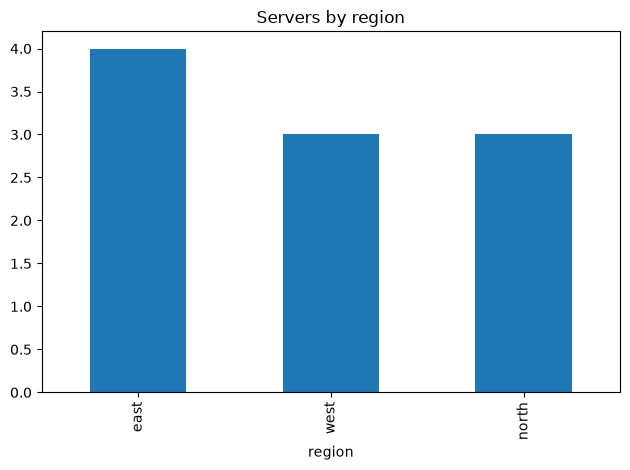

<Figure size 640x480 with 0 Axes>

In [11]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["region"].value_counts().plot(kind="bar", title="Servers by region")
plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()

### Your turn
Make a bar chart of servers per region instead of per status.

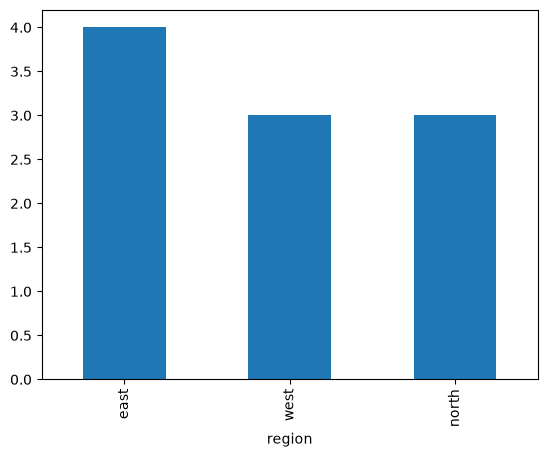

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

servers = pd.read_csv("../03 - Grouping, Sorting and Aggregating/examples/servers.csv")

servers["region"].value_counts().plot(kind="bar")

plt.show()

---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

In [ ]:
# your code here

import pandas as pd
import matplotlib.pyplot as plt

servers = pd.read_csv("../03 - Grouping, Sorting and Aggregating/examples/servers.csv")

servers["percent"] = (servers["used"] / servers["total"]) * 100

servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar")
plt.title("Servers by Status")
plt.show()

---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.